In [1]:
%matplotlib inline

# `networkx`

NetworkX lets us define graphs very easily, and then gives us a lot of different algorithms to analyze them. The steps are simple:

1. select a graph type: undirected (`Graph`) or directed (`DiGraph`) graph

2. populate the graph with nodes and/or edges. If we add an edge, the nodes are automatically added

3. analyze it (centrality, density, communities, ...) and plot it

## Our data: a (fictional) legislature

To make this concrete, we use a small, **fictional** legislature with 13 members (7 Democrats, 6 Republicans). We look at it in two ways:

1. **Bill co-sponsorship** (*undirected*): two legislators are connected if they sponsored the same bill together. Co-sponsoring is mutual, so the edge has no direction. The weight is the number of bills they sponsored together.

2. **Social media mentions** (*directed*): an arrow `A → B` means "A mentioned B". Mentioning is *not* mutual (A can mention B without B ever mentioning A), so the edges need a direction.

All names and numbers are made up for teaching purposes.

In [2]:
# --- Libraries ----------------------------------------------------------------
import matplotlib.pyplot as plt      # for plotting
import networkx as nx                # for building and analyzing networks
import pandas as pd                  # for tables (DataFrames)
import seaborn as sb                 # only used to make the plots look nicer
from itertools import combinations   # to create all possible pairs from a list
from collections import Counter      # to count how often something happens

sb.set_context('poster')             # bigger fonts in the plots

# --- Data 1: who co-sponsored which bill? ---------------------------------------
# Each bill (the key) maps to the list of legislators who sponsored it (the value)
bills = {
    # Democrats among themselves
    'H.R. 101: Infrastructure Renewal':   ['Alvarez', 'Brooks', 'Chen'],
    'H.R. 102: Healthcare Access':        ['Brooks', 'Diaz'],
    'H.R. 103: Clean Energy Tax Credit':  ['Chen', 'Diaz', 'Foster'],
    'H.R. 104: Voting Rights':            ['Alvarez', 'Evans'],
    'H.R. 105: Student Debt Relief':      ['Evans', 'Foster'],
    'H.R. 106: Minimum Wage':             ['Brooks', 'Chen'],
    # Republicans among themselves
    'H.R. 107: Border Security':          ['Grant', 'Hughes', 'Irwin'],
    'H.R. 108: Defense Budget':           ['Hughes', 'Jensen'],
    'H.R. 109: Tax Cuts':                 ['Grant', 'Keller'],
    'H.R. 110: Deregulation':             ['Irwin', 'Keller', 'Lopez'],
    'H.R. 111: Law Enforcement Funding':  ['Grant', 'Hughes'],
    # Bills that cross party lines (Morgan is the moderate Democrat)
    'H.R. 112: Veterans Care':            ['Alvarez', 'Morgan'],
    'H.R. 113: Rural Broadband':          ['Evans', 'Morgan'],
    'H.R. 114: Energy Independence':      ['Morgan', 'Hughes', 'Irwin'],
    'H.R. 115: Disaster Aid':             ['Morgan', 'Grant'],
    'H.R. 116: Opioid Task Force':        ['Chen', 'Keller'],
}

# --- The party of each legislator (D = Democrat, R = Republican) ----------------
party = {
    'Alvarez': 'D', 'Brooks': 'D', 'Chen': 'D', 'Diaz': 'D',
    'Evans': 'D', 'Foster': 'D', 'Morgan': 'D',     # Morgan is a moderate Democrat
    'Grant': 'R', 'Hughes': 'R', 'Irwin': 'R',
    'Jensen': 'R', 'Keller': 'R', 'Lopez': 'R',
}

print(len(bills), 'bills,', len(party), 'legislators')

16 bills, 13 legislators


## Creating graphs

We start with an empty **undirected** graph. (For a directed graph we would use `nx.DiGraph()` instead.)

In [3]:
# Create an empty undirected graph
G = nx.Graph()

# Count its nodes and edges (both are 0, because the graph is still empty)
print('Nodes:', G.number_of_nodes())
print('Edges:', G.number_of_edges())

Nodes: 0
Edges: 0


## Adding nodes

There are two ways to add nodes:
    * we can add individual nodes (`add_node(u)`) or
    * add them in batches (`add_nodes_from(x)`, where `x` is a list of nodes).

Nodes can also carry **attributes**, i.e., extra information such as the party of a legislator.

In [4]:
# Add one node at a time
G.add_node('Alvarez')
G.add_node('Brooks')

# Add several nodes at once.
# 'Brooks' is already in the graph, so it is NOT added a second time
G.add_nodes_from(['Brooks', 'Chen', 'Grant'])

# Add a node together with an attribute (here: the party)
G.add_node('Morgan', party='D')

print('Nodes:', G.nodes)
print('Number of nodes:', G.number_of_nodes())

Nodes: ['Alvarez', 'Brooks', 'Chen', 'Grant', 'Morgan']
Number of nodes: 5


## Adding edges

We can add edges the same way as nodes: individually (`add_edge(u, v)`), or in batches via `add_edges_from(x)`.
Edges are tuples of nodes. If a node is not in the graph when we add an edge, it gets automatically created:

In [5]:
# Add one edge: Alvarez and Brooks co-sponsored a bill
G.add_edge('Alvarez', 'Brooks')

# 'Hughes' is not in the graph yet, so networkx creates this node automatically
G.add_edge('Grant', 'Hughes')

# Add several edges at once: a list of (u, v) tuples
G.add_edges_from([('Brooks', 'Chen'), ('Alvarez', 'Chen'), ('Morgan', 'Grant')])

print('Number of nodes:', G.number_of_nodes())   # Hughes was added automatically
print('Number of edges:', G.number_of_edges())

Number of nodes: 6
Number of edges: 5


We can look at individual nodes by accessing them like this:

`graph['nodename']`

This gives us a dictionary of the neighboring nodes and the weight of the connections to them.

In [6]:
# Who is connected to Alvarez? (the {} means: no weight stored for this edge)
print(G['Alvarez'])

# The same information as a simple list, plus the number of connections (the "degree")
print(list(G.neighbors('Alvarez')))
print('Degree of Alvarez:', G.degree('Alvarez'))

{'Brooks': {}, 'Chen': {}}
['Brooks', 'Chen']
Degree of Alvarez: 2


If we want our edges to have a weight, we add it with the keyword `weight`:

In [7]:
# Add an edge with a weight, e.g. 3 = they co-sponsored three bills together
G.add_edge('Morgan', 'Alvarez', weight=3)

# Look at all neighbors of Morgan and the weight of each connection
# (edges without a weight just show an empty {})
G['Morgan']

AtlasView({'Grant': {}, 'Alvarez': {'weight': 3}})

## Adding nodes *and* edges from data

That was only a toy graph to learn the commands. Now let's build the **real** co-sponsorship graph from our `bills` data:

1. For every bill, look at all *pairs* of sponsors and count how often each pair shows up (= the edge weight).
2. Create the graph: one node per legislator (with the party as attribute), one weighted edge per pair.

In [8]:
# --- Step 1: count how often each pair of legislators co-sponsored a bill ---------
pair_counts = Counter()                       # works like a dictionary that starts every count at 0

for bill, sponsors in bills.items():          # go through every bill ...
    # combinations(x, 2) gives every possible pair of sponsors exactly once.
    # sorted() puts the names in alphabetical order first, so that ('Brooks', 'Alvarez')
    # and ('Alvarez', 'Brooks') are counted as the same pair.
    for p1, p2 in combinations(sorted(sponsors), 2):
        pair_counts[(p1, p2)] += 1            # +1 for every bill the pair shares

# --- Step 2: build the graph ---------------------------------------------------------
G = nx.Graph()                                # start again with an empty graph

# add every legislator as a node and store the party as a node attribute
for name, p in party.items():
    G.add_node(name, party=p)

# add one edge per pair; the weight is the number of shared bills
for (p1, p2), n_bills in pair_counts.items():
    # an edge is "cross-party" if the two legislators belong to different parties
    cross = party[p1] != party[p2]
    G.add_edge(p1, p2, weight=n_bills, cross_party=cross)

print('Nodes:', G.number_of_nodes())
print('Edges:', G.number_of_edges())

Nodes: 13
Edges: 23


### Properties

To get the set of nodes or edges, we can use the respective properties of the graph. With `data=True`, we also see the attributes:

In [9]:
# Show only the first three nodes and edges (the full lists are long)
print(list(G.nodes(data=True))[:3])
print()
print(list(G.edges(data=True))[:3])

[('Alvarez', {'party': 'D'}), ('Brooks', {'party': 'D'}), ('Chen', {'party': 'D'})]

[('Alvarez', 'Brooks', {'weight': 1, 'cross_party': False}), ('Alvarez', 'Chen', {'weight': 1, 'cross_party': False}), ('Alvarez', 'Evans', {'weight': 1, 'cross_party': False})]


Plotting
----

`networkx` also gives us the tools to plot our graph. A first quick plot is just one line:

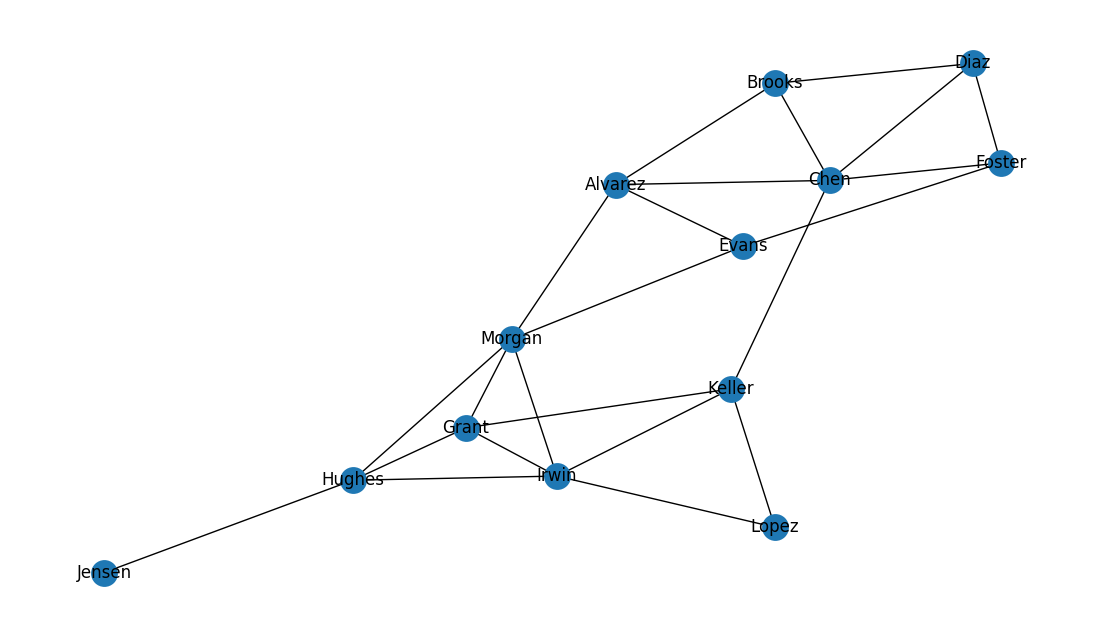

In [10]:
fig, ax = plt.subplots(figsize=(14, 8))

# the simplest possible plot
nx.draw(G, with_labels=True, ax=ax)

That shows the structure, but not much more. Let's use the **attributes** to make the plot informative:

* node color = party (blue = Democrat, red = Republican)
* edge width = number of co-sponsored bills
* edge color = green if the edge connects legislators from different parties

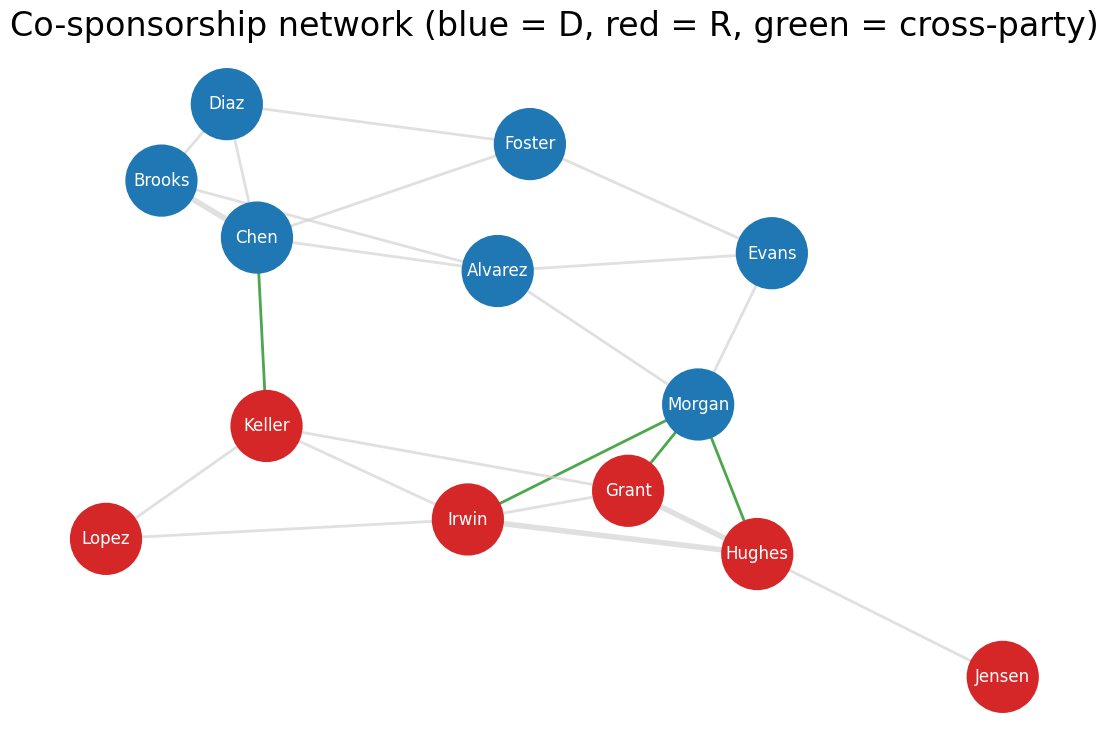

In [11]:
fig, ax = plt.subplots(figsize=(14, 9))

# A layout decides where each node is drawn. spring_layout pulls connected nodes
# together and pushes unconnected nodes apart. seed=42 makes the layout identical
# every time we run the code.
pos = nx.spring_layout(G, seed=42)

# Node colors: look up the party of each node and translate it into a color
party_colors = {'D': 'tab:blue', 'R': 'tab:red'}
node_colors = [party_colors[G.nodes[n]['party']] for n in G.nodes]

# Edge widths: the weight (= shared bills), multiplied by 2 to make the lines thicker
edge_widths = [G.edges[e]['weight'] * 2 for e in G.edges]

# Edge colors: green for cross-party edges, grey for all others
edge_colors = ['green' if G.edges[e]['cross_party'] else 'lightgrey' for e in G.edges]

# Draw nodes, labels and edges as three separate layers
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=2500, ax=ax)
nx.draw_networkx_labels(G, pos, font_color='white', font_size=12, ax=ax)
nx.draw_networkx_edges(G, pos, width=edge_widths, edge_color=edge_colors, alpha=0.7, ax=ax)

ax.set_axis_off()    # hide the axes, we do not need them for a network
ax.set_title('Co-sponsorship network (blue = D, red = R, green = cross-party)');

### Adjacency

We can get an adjacency matrix of the graph with `adj`. Each node maps to the set of nodes it is connected with, and the respective connection weight.

In [12]:
# Adjacency of a single node: its neighbors and the edge attributes
print(G.adj['Morgan'])

{'Alvarez': {'weight': 1, 'cross_party': False}, 'Evans': {'weight': 1, 'cross_party': False}, 'Hughes': {'weight': 1, 'cross_party': True}, 'Irwin': {'weight': 1, 'cross_party': True}, 'Grant': {'weight': 1, 'cross_party': True}}


The same information as a full **adjacency matrix** (a table with one row and one column per legislator). Each cell is the edge weight, and 0 means "no edge". Because our graph is undirected, the matrix is symmetric across the diagonal.

In [13]:
# Turn the graph into a table (DataFrame); weight='weight' fills the cells with the edge weights
adjacency = nx.to_pandas_adjacency(G, weight='weight').astype(int)
adjacency

,Alvarez,Brooks,Chen,Diaz,Evans,Foster,Morgan,Grant,Hughes,Irwin,Jensen,Keller,Lopez
Alvarez,0,1,1,0,1,0,1,0,0,0,0,0,0
Brooks,1,0,2,1,0,0,0,0,0,0,0,0,0
Chen,1,2,0,1,0,1,0,0,0,0,0,1,0
Diaz,0,1,1,0,0,1,0,0,0,0,0,0,0
Evans,1,0,0,0,0,1,1,0,0,0,0,0,0
Foster,0,0,1,1,1,0,0,0,0,0,0,0,0
Morgan,1,0,0,0,1,0,0,1,1,1,0,0,0
Grant,0,0,0,0,0,0,1,0,2,1,0,1,0
Hughes,0,0,0,0,0,0,1,2,0,2,1,0,0
Irwin,0,0,0,0,0,0,1,1,2,0,0,1,1


Graph Analysis
----

We can use some standard measures that assess how important a node is. These are called **centrality** measures. Which one to use depends on what "important" means for your question:

* **degree**: to how many other nodes a node $u$ is connected. In our example: with how many colleagues does a legislator co-sponsor bills? (`degree_centrality` is the same number divided by the maximum possible, i.e., the number of other nodes)

* **strength** (weighted degree): the sum of the edge weights. Here: how many co-sponsorships in total, counting every shared bill?

* **betweenness centrality**: how often the node is part of a shortest path between other nodes. Nodes with high betweenness are **brokers** or **bridges**. Here: who connects the two parties?

* **closeness centrality**: how close a node is, on average, to all other nodes (via the shortest paths). Here: who can reach everybody else in the fewest steps?

* **eigenvector centrality**: a node is important if it is connected to other important nodes. It is not only *how many*, but *who* you are connected to.

* **PageRank**: this is the algorithm used by Google (and developed by one of its founders, Larry Page). It takes into account how many nodes link to $u$ and how important those other nodes are. It is a variant of eigenvector centrality.

* **clustering coefficient**: how many of a node's neighbors are also connected to each other? A high value means the node sits inside a tight group.

We compute the values for each node and collect them in one table.

In [14]:
# Every measure returns a dictionary {node: value}. A DataFrame turns these into columns.
centrality = pd.DataFrame({
    # --- degree-based measures ---
    'degree':          dict(G.degree()),                    # number of co-sponsors
    'degree_centrality': nx.degree_centrality(G),           # degree / (number of other nodes)
    'strength':        dict(G.degree(weight='weight')),     # number of co-sponsorships (weighted)

    # --- path-based measures (ignore the weights by default) ---
    'betweenness':     nx.betweenness_centrality(G),        # how often on a shortest path between others
    'closeness':       nx.closeness_centrality(G),          # how close to everybody else

    # --- "importance of my neighbors" measures ---
    'eigenvector':     nx.eigenvector_centrality(G, max_iter=1000),  # connected to important nodes?
    'pagerank':        nx.pagerank(G),                      # uses the edge weights by default

    # --- local structure ---
    'clustering':      nx.clustering(G),                    # are my neighbors connected to each other?
})

# add the party as an extra column, so we can see who is who
centrality['party'] = pd.Series(nx.get_node_attributes(G, 'party'))

# sort by betweenness (largest first) and round to 2 decimals for readability
centrality.sort_values('betweenness', ascending=False).round(2)

,degree,degree_centrality,strength,betweenness,closeness,eigenvector,pagerank,clustering,party
Morgan,5,0.42,5,0.27,0.60,0.41,0.09,0.40,D
Chen,5,0.42,6,0.23,0.55,0.28,0.11,0.30,D
Keller,4,0.33,4,0.20,0.55,0.32,0.08,0.33,R
Hughes,4,0.33,6,0.17,0.48,0.32,0.11,0.50,R
Alvarez,4,0.33,4,0.13,0.55,0.28,0.08,0.33,D
Irwin,5,0.42,6,0.12,0.55,0.41,0.11,0.50,R
Evans,3,0.25,3,0.08,0.50,0.22,0.06,0.33,D
Grant,4,0.33,5,0.04,0.52,0.37,0.09,0.67,R
Foster,3,0.25,3,0.04,0.44,0.17,0.06,0.33,D
Brooks,3,0.25,4,0.02,0.44,0.18,0.08,0.67,D


Let's read the table. **Morgan**, the moderate Democrat who co-sponsors bills with Republicans, has the highest betweenness (0.27): Morgan is the main bridge between the two parties. **Chen** and **Keller** come next: they are the only cross-party pair *without* Morgan (they co-sponsored the opioid bill), so they form a second, smaller bridge. Morgan also has the highest closeness: Morgan can reach everybody in the fewest steps.

Notice that degree alone would not tell us this: Morgan, Chen and Irwin all have degree 5, but their betweenness is very different (0.27, 0.23, 0.12). Betweenness captures something that degree misses.

We can also store a measure **inside the graph** as a node attribute, and then use it, e.g., to scale the size of the nodes in the plot. In order to see the node properties, we have to use a slightly different syntax from seeing the neighbors:

`graph.nodes['nodename']` instead of `graph['nodename']`

In [15]:
# Store the betweenness of every node as a node attribute called 'betweenness'
nx.set_node_attributes(G, nx.betweenness_centrality(G), name='betweenness')

# Look at all attributes of one node
print(G.nodes['Morgan'])

{'party': 'D', 'betweenness': 0.27070707070707073}


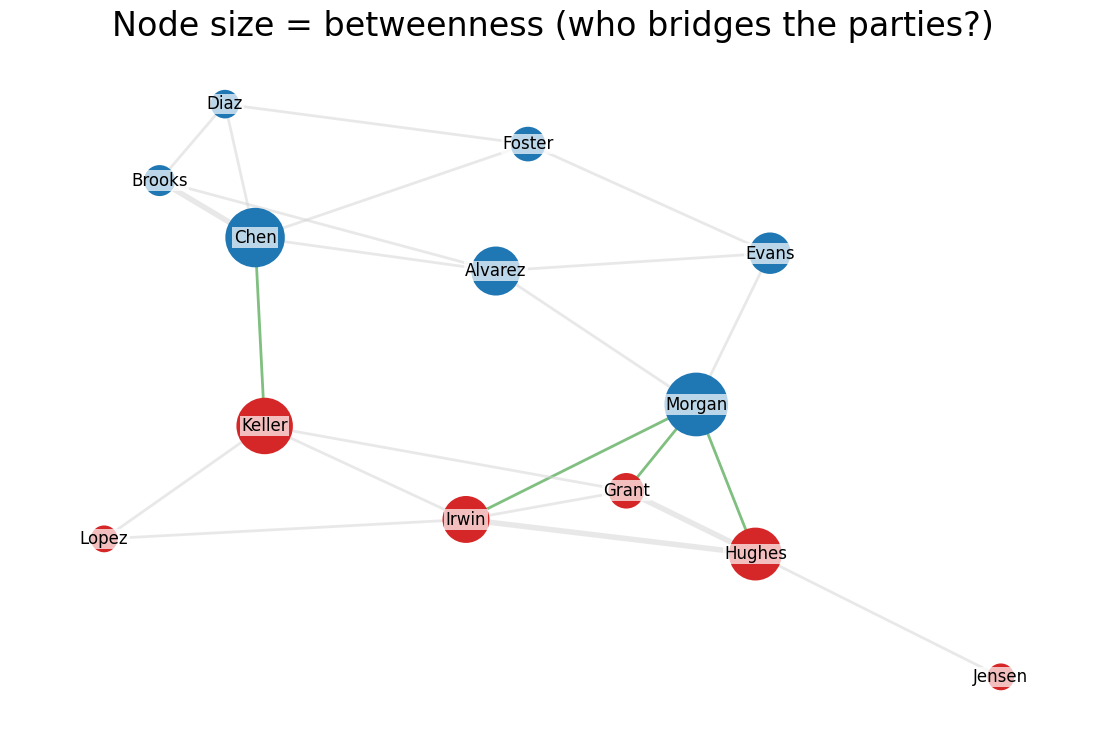

In [16]:
fig, ax = plt.subplots(figsize=(14, 9))

# Node size grows with betweenness (the 300 is a minimum size, so nobody disappears)
node_sizes = [300 + 6000 * G.nodes[n]['betweenness'] for n in G.nodes]

# (we reuse pos, node_colors, edge_widths and edge_colors from the plot above)
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=node_sizes, ax=ax)
# bbox puts a semi-transparent white box behind each label, so that it stays readable
# even on small or dark nodes
nx.draw_networkx_labels(G, pos, font_size=12, ax=ax,
                        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1))
nx.draw_networkx_edges(G, pos, width=edge_widths, edge_color=edge_colors, alpha=0.5, ax=ax)

ax.set_axis_off()
ax.set_title('Node size = betweenness (who bridges the parties?)');

### Network-level measures

So far we looked at individual nodes. We can also describe the **whole network** with a single number:

* **density**: the share of possible edges that actually exist (0 = no edges, 1 = everybody is connected to everybody)
* **average shortest path**: the average number of steps between two nodes. This is only defined if the graph is connected.
* **diameter**: the longest shortest path in the network
* **transitivity**: how often are "friends of my friends" also my friends? (the share of closed triangles)
* **assortativity**: do nodes connect to nodes that are *like them*? Here: do legislators co-sponsor with their own party? A value of 1 means perfect **homophily** (only same-party edges), 0 means no preference, and negative values mean that opposites attract.

In [17]:
print('Density:                ', round(nx.density(G), 2))
print('Connected?              ', nx.is_connected(G))       # one single connected piece?
print('Average shortest path:  ', round(nx.average_shortest_path_length(G), 2))
print('Diameter:               ', nx.diameter(G))
print('Transitivity:           ', round(nx.transitivity(G), 2))

# Share of edges that connect different parties:
# G.edges(data=True) gives (u, v, attributes), and we read the cross_party attribute
n_cross = sum(attrs['cross_party'] for u, v, attrs in G.edges(data=True))
print('Cross-party edges:      ', n_cross, 'of', G.number_of_edges())

# Assortativity by party: 1 = only same-party edges, 0 = random mixing
print('Party assortativity:    ', round(nx.attribute_assortativity_coefficient(G, 'party'), 2))

Density:                 0.29
Connected?               True
Average shortest path:   2.1
Diameter:                5
Transitivity:            0.45
Cross-party edges:       4 of 23
Party assortativity:     0.65


### Communities

**Community detection** finds groups of nodes that are more densely connected with each other than with the rest of the network. Here we use a simple algorithm (greedy modularity maximization). We can then check: do the groups the algorithm finds match the parties?

In [18]:
# Find communities (the algorithm does NOT know anything about the parties!)
communities = nx.community.greedy_modularity_communities(G)

# Print each community as a sorted list of names
for i, members in enumerate(communities):
    print('Community', i, ':', sorted(members))

# Modularity: how clearly separated are the communities? (higher = clearer groups)
print()
print('Modularity:', round(nx.community.modularity(G, communities), 2))

Community 0 : ['Grant', 'Hughes', 'Irwin', 'Jensen', 'Keller', 'Lopez', 'Morgan']
Community 1 : ['Alvarez', 'Brooks', 'Chen', 'Diaz', 'Evans', 'Foster']

Modularity: 0.38


The algorithm knows nothing about parties, yet it finds almost exactly the two parties. The one exception is **Morgan**: the moderate Democrat is grouped with the Republicans, because 3 of Morgan's 5 co-sponsors are Republicans. Together with the assortativity (0.65) and the fact that only 4 of 23 edges cross party lines, this shows strong partisan **homophily** in co-sponsoring.

Directed networks: who mentions whom?
----

Now the second dataset. Here the relation is **not mutual**: `Lopez → Grant` means "Lopez mentioned Grant". Each row is one edge with a `source` (who mentions) and a `target` (who is mentioned). This "edge list" format is very common, e.g., for data scraped from social media.

In [19]:
# define data: each tuple is (source, target) = "source mentioned target"
mentions = [
    # Democrats mostly mention Democrats ...
    ('Alvarez', 'Brooks'), ('Chen', 'Brooks'), ('Diaz', 'Brooks'), ('Evans', 'Brooks'), ('Foster', 'Brooks'),
    ('Brooks', 'Alvarez'), ('Alvarez', 'Chen'), ('Chen', 'Alvarez'), ('Foster', 'Alvarez'),
    ('Diaz', 'Evans'), ('Evans', 'Diaz'),
    # ... and Republicans mostly mention Republicans
    ('Hughes', 'Grant'), ('Irwin', 'Grant'), ('Jensen', 'Grant'), ('Keller', 'Grant'), ('Lopez', 'Grant'),
    ('Grant', 'Hughes'), ('Jensen', 'Keller'), ('Keller', 'Jensen'),
    # Lopez is very active on social media and mentions many people
    ('Lopez', 'Hughes'), ('Lopez', 'Irwin'), ('Lopez', 'Jensen'), ('Lopez', 'Keller'), ('Lopez', 'Alvarez'),
    # the two party leaders attack each other
    ('Grant', 'Brooks'), ('Brooks', 'Grant'),
    # Morgan (moderate Democrat) talks to both sides
    ('Morgan', 'Brooks'), ('Morgan', 'Grant'), ('Alvarez', 'Morgan'), ('Hughes', 'Morgan'),
]

# put the edge list into a DataFrame (a table with two columns)
df = pd.DataFrame(mentions, columns=['source', 'target'])
df.head()

,source,target
0,Alvarez,Brooks
1,Chen,Brooks
2,Diaz,Brooks
3,Evans,Brooks
4,Foster,Brooks


In [20]:
# Create a DIRECTED graph from the table:
# source/target say which columns hold the start and the end of each arrow
D = nx.from_pandas_edgelist(df, source='source', target='target', create_using=nx.DiGraph())

# Add the party as a node attribute (we already have the party dictionary from above)
nx.set_node_attributes(D, party, name='party')

print('Nodes:', D.number_of_nodes())
print('Edges:', D.number_of_edges())

Nodes: 13
Edges: 30


In a directed graph, "neighbor" is no longer enough: we have to say in which **direction**.

* `successors(u)`: the nodes that `u` points **to** (whom does `u` mention?). The number of these is the **out-degree**.
* `predecessors(u)`: the nodes that point **to** `u` (who mentions `u`?). The number of these is the **in-degree**.

In [21]:
print('Alvarez mentions:       ', list(D.successors('Alvarez')))
print('Alvarez is mentioned by:', list(D.predecessors('Alvarez')))
print()
print('Out-degree of Alvarez:', D.out_degree('Alvarez'))
print('In-degree of Alvarez: ', D.in_degree('Alvarez'))

Alvarez mentions:        ['Brooks', 'Chen', 'Morgan']
Alvarez is mentioned by: ['Brooks', 'Chen', 'Foster', 'Lopez']

Out-degree of Alvarez: 3
In-degree of Alvarez:  4


### Centrality in directed networks

For directed networks, many measures come in two versions: **in** and **out**.

* **in-degree**: how many arrows point *to* me? (popularity, attention received)
* **out-degree**: how many arrows start *at* me? (activity, attention given)
* **closeness (in)**: how quickly can *others reach me* by following the arrows? A high value means I am "easy to reach".
* **closeness (out)**: how quickly can *I reach others* by following the arrows? A high value means I can "get to everybody quickly".
* **reach (in / out)**: simply count the nodes that can reach me (in) or that I can reach (out), by following arrows over any number of steps.
* **betweenness**: as before, but only paths that follow the direction of the arrows count.
* **eigenvector / PageRank**: being pointed at by important nodes makes me important.
* **hub and authority** (the HITS algorithm): a good **authority** is pointed at by many good hubs, and a good **hub** points to many good authorities. In our example: authorities are the accounts that get mentioned by those who mention the "right" people.

**Careful with closeness:** `networkx` computes closeness for directed graphs using *incoming* paths. That is our closeness (in). To get closeness (out), we flip all arrows with `D.reverse()` and compute it again.

In [22]:
# Closeness (in): networkx default for directed graphs (uses paths that arrive at the node)
closeness_in = nx.closeness_centrality(D)

# Closeness (out): D.reverse() flips every arrow, so "arriving at" becomes "starting from"
closeness_out = nx.closeness_centrality(D.reverse())

# HITS returns TWO dictionaries at once: hubs and authorities
hubs, authorities = nx.hits(D)

# Reach: nx.ancestors(D, n) = all nodes that can get to n, nx.descendants(D, n) = all nodes n can get to
reach_in  = {n: len(nx.ancestors(D, n))   for n in D.nodes}
reach_out = {n: len(nx.descendants(D, n)) for n in D.nodes}

# Collect everything in one table
centrality_D = pd.DataFrame({
    'in_degree':      dict(D.in_degree()),                  # how many mention me?
    'out_degree':     dict(D.out_degree()),                 # how many do I mention?
    'betweenness':    nx.betweenness_centrality(D),         # broker between others (following arrows)
    'closeness_in':   closeness_in,                         # how easily am I reached?
    'closeness_out':  closeness_out,                        # how easily do I reach others?
    'reach_in':       reach_in,                             # how many can (eventually) reach me?
    'reach_out':      reach_out,                            # how many can I (eventually) reach?
    'eigenvector':    nx.eigenvector_centrality(D, max_iter=1000),  # pointed at by important nodes?
    'pagerank':       nx.pagerank(D),                       # same idea, handles all graphs well
    'hub':            hubs,                                 # points to good authorities
    'authority':      authorities,                          # pointed at by good hubs
})

# add the party as an extra column
centrality_D['party'] = pd.Series(nx.get_node_attributes(D, 'party'))

# sort by in-degree: who gets mentioned the most?
centrality_D.sort_values('in_degree', ascending=False).round(2)

,in_degree,out_degree,betweenness,closeness_in,closeness_out,reach_in,reach_out,eigenvector,pagerank,hub,authority,party
Brooks,7,2,0.20,0.71,0.26,12,5,0.63,0.24,0.09,0.17,D
Grant,7,2,0.18,0.71,0.23,12,5,0.54,0.24,0.06,0.24,R
Alvarez,4,3,0.13,0.50,0.26,12,5,0.37,0.14,0.06,0.16,D
Hughes,2,2,0.03,0.44,0.19,12,5,0.25,0.11,0.07,0.09,R
Jensen,2,2,0.00,0.17,0.26,2,7,0.00,0.02,0.08,0.09,R
Keller,2,2,0.00,0.17,0.26,2,7,0.00,0.02,0.08,0.09,R
Morgan,2,2,0.02,0.44,0.23,12,5,0.29,0.10,0.10,0.05,D
Chen,1,2,0.00,0.34,0.23,12,5,0.17,0.05,0.08,0.02,D
Diaz,1,2,0.00,0.08,0.27,1,7,0.00,0.02,0.04,0.02,D
Evans,1,2,0.00,0.08,0.27,1,7,0.00,0.02,0.04,0.02,D


Compare the columns:

* **Brooks** and **Grant** (the party leaders) are each mentioned by 7 colleagues (in-degree). They also have the highest PageRank and betweenness: they mention each other, which is one of the few links between the two camps. Both are easy to reach (closeness in = 0.71).
* **Grant** has a higher *authority* score than Brooks, because Grant is mentioned by **Lopez**, the most active *hub*.
* **Lopez** has the highest out-degree (6), hub score and closeness (out): very active, and can reach everybody quickly. But nobody mentions Lopez (in-degree 0), so closeness (in) and reach (in) are 0. The same is true for **Foster**.
* **Keller** and **Jensen** both have an in-degree of 2, but a low reach (in): they are only mentioned by Lopez and by each other, so almost nobody can *reach* them.
* The eigenvector centrality is (almost) 0 for several nodes: in a directed network, only nodes that are pointed at by the well-connected core get a value. PageRank avoids this problem, which is why it is used more often.

Which measure should you use? Ask what "important" means in your question:

| Question | Measure |
|---|---|
| Who gets the most attention? | in-degree, authority, PageRank |
| Who is the most active? | out-degree, hub |
| Who connects different groups? | betweenness |
| Whose message can reach everybody quickly? | closeness (out), reach (out) |
| Who is easy to reach for everybody else? | closeness (in), reach (in) |

### Plotting a directed network

We use the same ingredients as before: node color = party, node size = in-degree (attention received). New: the edges are now **arrows**.

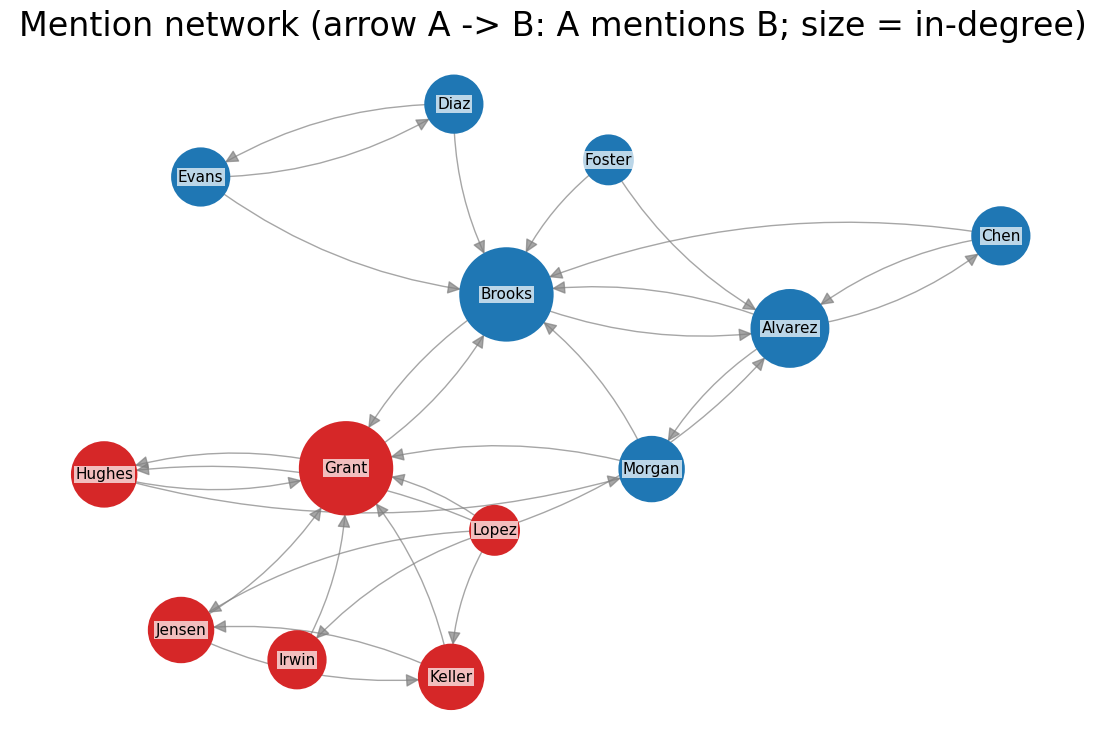

In [23]:
fig, ax = plt.subplots(figsize=(14, 9))

# layout: kamada_kawai usually gives a tidier picture than spring_layout for small networks
pos_D = nx.kamada_kawai_layout(D)

# node color by party, node size by in-degree (the 1200 is a minimum size)
node_colors_D = [party_colors[D.nodes[n]['party']] for n in D.nodes]
node_sizes_D  = [1200 + 450 * D.in_degree(n) for n in D.nodes]

nx.draw_networkx_nodes(D, pos_D, node_color=node_colors_D, node_size=node_sizes_D, ax=ax)
nx.draw_networkx_labels(D, pos_D, font_size=11, ax=ax,
                        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1))

# arrows=True draws the arrowheads.
# connectionstyle bends the edges a little, so that A -> B and B -> A do not lie on top of each other.
# node_size tells networkx where the nodes end, so the arrowheads stop at the border of the node.
nx.draw_networkx_edges(D, pos_D, arrows=True, arrowsize=20, edge_color='grey', alpha=0.7,
                       connectionstyle='arc3,rad=0.15', node_size=node_sizes_D, ax=ax)

ax.set_axis_off()
ax.set_title('Mention network (arrow A -> B: A mentions B; size = in-degree)');

### Network-level measures for directed networks

Some network measures are specific to directed graphs, e.g.:

* **reciprocity**: the share of edges that are returned (`A → B` *and* `B → A`). Do legislators mention each other back?
* **weakly connected**: the graph is connected if we ignore the direction of the arrows
* **strongly connected**: every node can reach every other node by *following* the arrows (much stricter!)

In [24]:
# Find the largest *weakly* connected component of the directed graph D.
# A weakly connected component is a set of nodes that are connected
# if we ignore the direction of the edges.
largest_cc = max(nx.weakly_connected_components(D), key=len)

# Create a subgraph containing only the nodes in that largest weakly connected component.
# Then convert this subgraph to an undirected graph so that average path length
# can be computed without requiring strong connectivity.
subD = D.subgraph(largest_cc).to_undirected()

# Compute the average shortest path length for the undirected subgraph.
# This gives a measure of how easily information (or influence) could spread
# through the main part of the network.
avg_path = nx.average_shortest_path_length(subD)

# Compute the network density: the proportion of possible edges that actually exist.
density = nx.density(D)

# Compute the reciprocity of the directed network:
# the proportion of edges where A→B is matched by B→A.
reciprocity = nx.reciprocity(D)

print('Density:                    ', round(density, 2))
print('Reciprocity:                ', round(reciprocity, 2))
print('Average shortest path:      ', round(avg_path, 2))

# How many separate pieces does the network have?
print('Weakly connected pieces:    ', nx.number_weakly_connected_components(D))
print('Strongly connected pieces:  ', nx.number_strongly_connected_components(D))

# Do legislators mention their own party? (same idea as assortativity before)
print('Party assortativity:        ', round(nx.attribute_assortativity_coefficient(D, 'party'), 2))

Density:                     0.19
Reciprocity:                 0.4
Average shortest path:       1.92
Weakly connected pieces:     1
Strongly connected pieces:   6
Party assortativity:         0.67
